In [1]:
#%pip install pandas numpy scikit-learn

In [2]:
print("Hello, Jupyter!")
import pandas as pd
import numpy as np

Hello, Jupyter!


In [3]:
import sklearn

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Scikit-learn:", sklearn.__version__)

Pandas: 3.0.6
NumPy: 2.4.6
Scikit-learn: 1.9.1


In [4]:
from sklearn.model_selection import train_test_split
from matplotlib import pyplot as plt
import seaborn as sns

In [5]:
!curl -L -o data-week-6.csv 'https://raw.githubusercontent.com/alexeygrigorev/mlbookcamp-code/master/chapter-06-trees/CreditScoring.csv'


  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100  178k  100  178k    0     0   230k      0 --:--:-- --:--:-- --:--:--  230k


In [6]:
df = pd.read_csv('data-week-6.csv')
df.head()

,Status,Seniority,Home,Time,Age,Marital,Records,Job,Expenses,Income,Assets,Debt,Amount,Price
0,1,9,1,60,30,2,1,3,73,129,0,0,800,846
1,1,17,1,60,58,3,1,1,48,131,0,0,1000,1658
2,2,10,2,36,46,2,2,3,90,200,3000,0,2000,2985
3,1,0,1,60,24,1,1,1,63,182,2500,0,900,1325
4,1,0,1,36,26,1,1,1,46,107,0,0,310,910


In [7]:
df.dtypes

Status       int64
Seniority    int64
Home         int64
Time         int64
Age          int64
Marital      int64
Records      int64
Job          int64
Expenses     int64
Income       int64
Assets       int64
Debt         int64
Amount       int64
Price        int64
dtype: object

In [8]:
df.isnull().sum()

Status       0
Seniority    0
Home         0
Time         0
Age          0
Marital      0
Records      0
Job          0
Expenses     0
Income       0
Assets       0
Debt         0
Amount       0
Price        0
dtype: int64

In [9]:
df = pd.read_csv('data-week-6.csv')

df.columns = df.columns.str.lower().str.replace(' ', '_')


In [10]:
# Even though all are numerical columns, it doesn't make sense, they have coded categorical values as numerical format using R, like 1,2,3,4.etc.. 

# lets use MAP function to change it

status = {
    1:'ok',
    2:'default',
    0:'unk'
}


df.status = df.status.map(status)

home_values = {
    1: 'rent',
    2: 'owner',
    3: 'private',
    4: 'ignore',
    5: 'parents',
    6: 'other',
    0: 'unk'
}

df.home = df.home.map(home_values)

marital_values = {
    1: 'single',
    2: 'married',
    3: 'widow',
    4: 'separated',
    5: 'divorced',
    0: 'unk'
}

df.marital = df.marital.map(marital_values)

records_values = {
    1: 'no',
    2: 'yes',
    0: 'unk'
}

df.records = df.records.map(records_values)

job_values = {
    1: 'fixed',
    2: 'partime',
    3: 'freelance',
    4: 'others',
    0: 'unk'
}

df.job = df.job.map(job_values)

In [11]:
df.head()

,status,seniority,home,time,age,marital,records,job,expenses,income,assets,debt,amount,price
0,ok,9,rent,60,30,married,no,freelance,73,129,0,0,800,846
1,ok,17,rent,60,58,widow,no,fixed,48,131,0,0,1000,1658
2,default,10,owner,36,46,married,yes,freelance,90,200,3000,0,2000,2985
3,ok,0,rent,60,24,single,no,fixed,63,182,2500,0,900,1325
4,ok,0,rent,36,26,single,no,fixed,46,107,0,0,310,910


In [12]:
df.describe().round()

,seniority,time,age,expenses,income,assets,debt,amount,price
count,4455.0,4455.0,4455.0,4455.0,4455.0,4455.0,4455.0,4455.0,4455.0
mean,8.0,46.0,37.0,56.0,763317.0,1060341.0,404382.0,1039.0,1463.0
std,8.0,15.0,11.0,20.0,8703625.0,10217569.0,6344253.0,475.0,628.0
min,0.0,6.0,18.0,35.0,0.0,0.0,0.0,100.0,105.0
25%,2.0,36.0,28.0,35.0,80.0,0.0,0.0,700.0,1118.0
50%,5.0,48.0,36.0,51.0,120.0,3500.0,0.0,1000.0,1400.0
75%,12.0,60.0,45.0,72.0,166.0,6000.0,0.0,1300.0,1692.0
max,48.0,72.0,68.0,180.0,99999999.0,99999999.0,99999999.0,5000.0,11140.0


In [13]:
for c in ['income', 'assets', 'debt']:
    df[c] = df[c].replace(to_replace=99999999, value=np.nan)

In [14]:
df.isnull().sum()

status        0
seniority     0
home          0
time          0
age           0
marital       0
records       0
job           0
expenses      0
income       34
assets       47
debt         18
amount        0
price         0
dtype: int64

In [15]:
df.describe().round()

,seniority,time,age,expenses,income,assets,debt,amount,price
count,4455.0,4455.0,4455.0,4455.0,4421.0,4408.0,4437.0,4455.0,4455.0
mean,8.0,46.0,37.0,56.0,131.0,5403.0,343.0,1039.0,1463.0
std,8.0,15.0,11.0,20.0,86.0,11573.0,1246.0,475.0,628.0
min,0.0,6.0,18.0,35.0,0.0,0.0,0.0,100.0,105.0
25%,2.0,36.0,28.0,35.0,80.0,0.0,0.0,700.0,1118.0
50%,5.0,48.0,36.0,51.0,120.0,3000.0,0.0,1000.0,1400.0
75%,12.0,60.0,45.0,72.0,165.0,6000.0,0.0,1300.0,1692.0
max,48.0,72.0,68.0,180.0,959.0,300000.0,30000.0,5000.0,11140.0


In [16]:
df = df[df.status!='unk'].reset_index(drop=True)

In [17]:
df.shape

(4454, 14)

In [18]:

from sklearn.model_selection import train_test_split

In [19]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

y_train = (df_train.status == 'default').astype('int').values
y_val = (df_val.status == 'default').astype('int').values
y_test = (df_test.status == 'default').astype('int').values

del df_train['status']
del df_val['status']
del df_test['status']

In [20]:
## Decision Tree

from sklearn.tree import DecisionTreeClassifier
from sklearn.feature_extraction import DictVectorizer
from sklearn.metrics import roc_auc_score


In [21]:
train_dicts = df_train.fillna(0).to_dict(orient='records')

In [22]:
dv=DictVectorizer(sparse=False)

X_train = dv.fit_transform(train_dicts)

In [23]:
dv.get_feature_names_out()

array(['age', 'amount', 'assets', 'debt', 'expenses', 'home=ignore',
       'home=other', 'home=owner', 'home=parents', 'home=private',
       'home=rent', 'home=unk', 'income', 'job=fixed', 'job=freelance',
       'job=others', 'job=partime', 'job=unk', 'marital=divorced',
       'marital=married', 'marital=separated', 'marital=single',
       'marital=unk', 'marital=widow', 'price', 'records=no',
       'records=yes', 'seniority', 'time'], dtype=object)

In [24]:
dt = DecisionTreeClassifier()
dt.fit(X_train, y_train)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of sampl

In [25]:
val_dicts = df_val.fillna(0).to_dict(orient='records')
x_val = dv.transform(val_dicts)

In [26]:
y_pred = dt.predict_proba(x_val)[:,1]

In [27]:
from sklearn.metrics import roc_auc_score

print(df.status.value_counts())
print(df.status.unique())

status
ok         3200
default    1254
Name: count, dtype: int64
<StringArray>
['ok', 'default']
Length: 2, dtype: str


In [28]:

print(np.unique(y_val, return_counts=True))

(array([0, 1]), array([645, 246]))


In [29]:
print(np.unique(y_pred, return_counts=True))

(array([0., 1.]), array([640, 251]))


In [30]:
roc_auc_score(y_val, y_pred)

0.6395443373038382

In [31]:
# let's check for training dataset

y_pred = dt.predict_proba(X_train)[:,1]
roc_auc_score(y_train, y_pred)

1.0

In [32]:
## u see area under the curve is 1 for training datset. which means it's memorizing the pattern from training data and overfitting it. when it sees a new example, it is clueless

# depth is unrestricted here , it can go any level deep which can result in over fitting

In [33]:
dt = DecisionTreeClassifier(max_depth=3)
dt.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",3
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples 

In [34]:
# let's check for training dataset

y_pred = dt.predict_proba(X_train)[:,1]
auc = roc_auc_score(y_train, y_pred)
print('train: ', auc)


y_pred = dt.predict_proba(x_val)[:,1]
auc = roc_auc_score(y_val, y_pred)
print('val: ', auc)

train:  0.7769739797926325
val:  0.7519852524106636


In [35]:
## Now it's working much better than the over fit model

## we can visualize the tree

In [36]:
from sklearn.tree import export_text

In [37]:
print(export_text(dt, feature_names=dv.get_feature_names_out()))

|--- income <= 89.50
|   |--- seniority <= 2.50
|   |   |--- records=yes <= 0.50
|   |   |   |--- class: 1
|   |   |--- records=yes >  0.50
|   |   |   |--- class: 1
|   |--- seniority >  2.50
|   |   |--- records=yes <= 0.50
|   |   |   |--- class: 0
|   |   |--- records=yes >  0.50
|   |   |   |--- class: 1
|--- income >  89.50
|   |--- records=no <= 0.50
|   |   |--- seniority <= 4.50
|   |   |   |--- class: 1
|   |   |--- seniority >  4.50
|   |   |   |--- class: 0
|   |--- records=no >  0.50
|   |   |--- job=partime <= 0.50
|   |   |   |--- class: 0
|   |   |--- job=partime >  0.50
|   |   |   |--- class: 0



In [38]:
##The question is: how does the learning algorithm decide which condition and which threshold to use at each split?

## Decision tree algorithm


In [39]:
data = [
    [8000, 'default'],
    [2000, 'default'],
    [   0, 'default'],
    [5000, 'ok'],
    [5000, 'ok'],
    [4000, 'ok'],
    [9000, 'ok'],
    [3000, 'default'],
]

df_example = pd.DataFrame(data, columns=['assets', 'status'])

In [40]:
df_example

,assets,status
0,8000,default
1,2000,default
2,0,default
3,5000,ok
4,5000,ok
5,4000,ok
6,9000,ok
7,3000,default


In [41]:
df_example.sort_values('assets')

,assets,status
2,0,default
1,2000,default
7,3000,default
5,4000,ok
3,5000,ok
4,5000,ok
0,8000,default
6,9000,ok


In [42]:
Ts = [0,2000,3000,4000,5000,6000] # possible thresholds for splitting

In [43]:
for T in Ts:
    print(T)
    df_left = df_example[df_example.assets <=T]
    df_right = df_example[df_example.assets >T]

    display(df_left)

    display(df_left.status.value_counts(normalize=True))
    display(df_right)
    display(df_right.status.value_counts(normalize=True))

    print()


## check the misclassification rate, for 4000 TS, it is 25% both default and not default.  DO weighted average

0


,assets,status
2,0,default


status
default    1.0
Name: proportion, dtype: float64

,assets,status
0,8000,default
1,2000,default
3,5000,ok
4,5000,ok
5,4000,ok
6,9000,ok
7,3000,default


status
ok         0.571429
default    0.428571
Name: proportion, dtype: float64


2000


,assets,status
1,2000,default
2,0,default


status
default    1.0
Name: proportion, dtype: float64

,assets,status
0,8000,default
3,5000,ok
4,5000,ok
5,4000,ok
6,9000,ok
7,3000,default


status
ok         0.666667
default    0.333333
Name: proportion, dtype: float64


3000


,assets,status
1,2000,default
2,0,default
7,3000,default


status
default    1.0
Name: proportion, dtype: float64

,assets,status
0,8000,default
3,5000,ok
4,5000,ok
5,4000,ok
6,9000,ok


status
ok         0.8
default    0.2
Name: proportion, dtype: float64


4000


,assets,status
1,2000,default
2,0,default
5,4000,ok
7,3000,default


status
default    0.75
ok         0.25
Name: proportion, dtype: float64

,assets,status
0,8000,default
3,5000,ok
4,5000,ok
6,9000,ok


status
ok         0.75
default    0.25
Name: proportion, dtype: float64


5000


,assets,status
1,2000,default
2,0,default
3,5000,ok
4,5000,ok
5,4000,ok
7,3000,default


status
default    0.5
ok         0.5
Name: proportion, dtype: float64

,assets,status
0,8000,default
6,9000,ok


status
default    0.5
ok         0.5
Name: proportion, dtype: float64


6000


,assets,status
1,2000,default
2,0,default
3,5000,ok
4,5000,ok
5,4000,ok
7,3000,default


status
default    0.5
ok         0.5
Name: proportion, dtype: float64

,assets,status
0,8000,default
6,9000,ok


status
default    0.5
ok         0.5
Name: proportion, dtype: float64

In [44]:
# # finding the best split algorithm:

# for f in features: 
#     find all thresholds for F 
#     for t in thersholds:
#         split datset using 'F>T' conditoion
#         compute the impurity of the split.

# select condition with the lowest impurity.

### stopping criteria

#1. group is already pure
#2. depth limit, stop if max depth is reached.
#3. minimum size of the group

In [45]:
# Parameter tuning.

In [46]:
for d in [1,2,3,4,5,6,7,8,10,15,20,None]:
    dt = DecisionTreeClassifier(max_depth=d)
    dt.fit(X_train,y_train)

    y_pred = dt.predict_proba(x_val)[:,1]
    auc = roc_auc_score(y_val, y_pred)

    print('%4s -> %.3f' % (d,auc))


# we can see its best at 4,5,6

   1 -> 0.616
   2 -> 0.711
   3 -> 0.752
   4 -> 0.773
   5 -> 0.765
   6 -> 0.731
   7 -> 0.738
   8 -> 0.706
  10 -> 0.668
  15 -> 0.646
  20 -> 0.641
None -> 0.647


In [47]:
scores = []

for d in [4,5,6]:
    for s in [1,2,4,5,10,15,100,200,500]:
        dt = DecisionTreeClassifier(max_depth=d, min_samples_leaf=s)
        dt.fit(X_train,y_train)

        y_pred = dt.predict_proba(x_val)[:,1]
        auc = roc_auc_score(y_val, y_pred)

        scores.append((d,s,auc))

        print('(%s, %d) -> %.3f' % (d,s,auc))


## Here we see highest auc is at 6,15 with 78%

(4, 1) -> 0.773
(4, 2) -> 0.773
(4, 4) -> 0.777
(4, 5) -> 0.777
(4, 10) -> 0.778
(4, 15) -> 0.777
(4, 100) -> 0.777
(4, 200) -> 0.762
(4, 500) -> 0.687
(5, 1) -> 0.765
(5, 2) -> 0.765
(5, 4) -> 0.771
(5, 5) -> 0.774
(5, 10) -> 0.776
(5, 15) -> 0.780
(5, 100) -> 0.774
(5, 200) -> 0.762
(5, 500) -> 0.687
(6, 1) -> 0.730
(6, 2) -> 0.732
(6, 4) -> 0.746
(6, 5) -> 0.748
(6, 10) -> 0.759
(6, 15) -> 0.783
(6, 100) -> 0.782
(6, 200) -> 0.762
(6, 500) -> 0.687


In [48]:

column  = ['max_depth', 'min_samples_leaf', 'auc']
df_scores = pd.DataFrame(scores, columns=column)

In [49]:
df_scores.sort_values(by='auc', ascending=False)

,max_depth,min_samples_leaf,auc
23,6,15,0.782895
24,6,100,0.782089
14,5,15,0.779605
4,4,10,0.777523
5,4,15,0.777163
6,4,100,0.777031
2,4,4,0.776927
3,4,5,0.776927
13,5,10,0.776284
15,5,100,0.774167


In [50]:
df_scores_pivot = df_scores.pivot(index='min_samples_leaf', columns=['max_depth'], values = ['auc'])

df_scores_pivot.round(3)

auc              
max_depth             4      5      6
min_samples_leaf                     
1                 0.773  0.765  0.730
2                 0.773  0.765  0.732
4                 0.777  0.771  0.746
5                 0.777  0.774  0.748
10                0.778  0.776  0.759
15                0.777  0.780  0.783
100               0.777  0.774  0.782
200               0.762  0.762  0.762
500               0.687  0.687  0.687

In [51]:
import seaborn as sns

<Axes: xlabel='None-max_depth', ylabel='min_samples_leaf'>

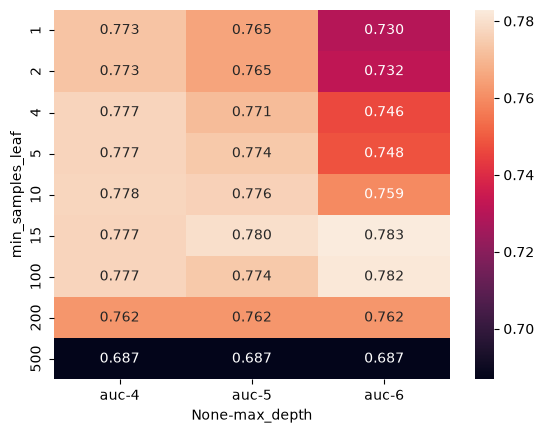

In [52]:
sns.heatmap(df_scores_pivot, annot=True, fmt='.3f')

In [53]:
## Ensemble and Random Forest

from sklearn.ensemble import RandomForestClassifier

In [54]:
rf = RandomForestClassifier(n_estimators=10, random_state=1)
rf.fit(X_train,y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",10
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",1
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap

In [55]:
y_pred = rf.predict_proba(x_val)[:,1]

In [56]:
roc_auc_score(y_val, y_pred)

0.7800340328984685

In [57]:
rf.predict_proba(x_val[[0]])

array([[0.6, 0.4]])

In [58]:
scores = []
for n in range( 10,201, 10):
    rf = RandomForestClassifier(n_estimators=n, random_state=1)
    rf.fit(X_train,y_train)
    y_pred = rf.predict_proba(x_val)[:,1]
    auc = roc_auc_score(y_val, y_pred)
    scores.append((n,auc))

In [59]:
df_scores = pd.DataFrame(scores,columns=['n_estimators','auc'])

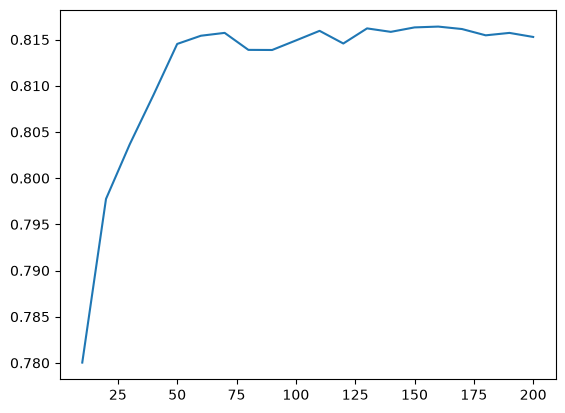

In [60]:
plt.plot(df_scores.n_estimators, df_scores.auc)

In [61]:
scores = []

for d in [5,10,15]:
    for n in range( 10,201, 10):
        rf = RandomForestClassifier(n_estimators=n, max_depth=d ,random_state=1)
        rf.fit(X_train,y_train)
        y_pred = rf.predict_proba(x_val)[:,1]
        auc = roc_auc_score(y_val, y_pred)
        scores.append((d, n,auc))

columns=['max_depth','n_estimators', 'auc']

df_scores = pd.DataFrame(scores,columns = columns)

df_scores.head()

,max_depth,n_estimators,auc
0,5,10,0.811908
1,5,20,0.809432
2,5,30,0.808039
3,5,40,0.808968
4,5,50,0.811634


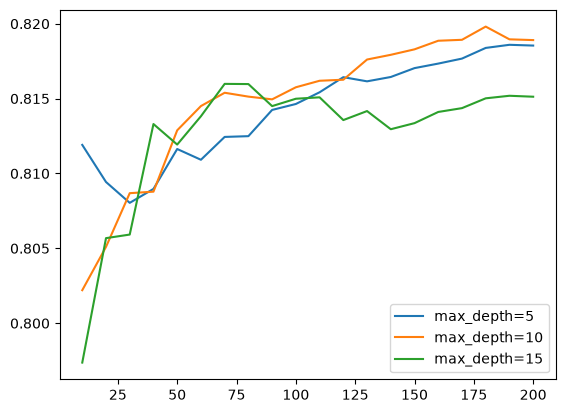

In [62]:
for d in [5,10,15]:
    df_subset = df_scores[df_scores.max_depth == d]
    plt.plot(df_subset.n_estimators, df_subset.auc, label='max_depth=%d' % d)
    plt.legend()

In [63]:
## value of max depth = 10 makes sense at around 175 

max_depth=10

scores = []

for d in [1,3,5,10,50]:
    for n in range( 10,201, 10):
        rf = RandomForestClassifier(n_estimators=n, max_depth=max_depth, min_samples_leaf=d,random_state=1)
        rf.fit(X_train,y_train)
        y_pred = rf.predict_proba(x_val)[:,1]
        auc = roc_auc_score(y_val, y_pred)
        scores.append((d,max_depth, n,auc))

columns=['min_sample_leaf','max_depth','n_estimators', 'auc']

df_scores = pd.DataFrame(scores,columns = columns)

df_scores.head()

,min_sample_leaf,max_depth,n_estimators,auc
0,1,10,10,0.802206
1,1,10,20,0.805099
2,1,10,30,0.808685
3,1,10,40,0.808786
4,1,10,50,0.812882


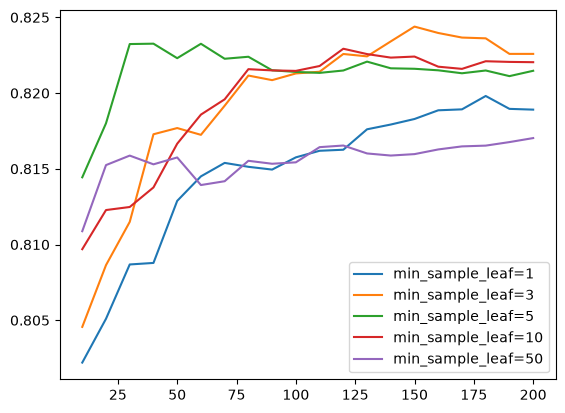

In [64]:
for d in [1,3,5,10,50]:
    df_subset = df_scores[df_scores.min_sample_leaf == d]
    plt.plot(df_subset.n_estimators, df_subset.auc, label='min_sample_leaf=%d' % d)

plt.legend()

In [65]:
## min sample leaf of 3 gives the best mode

min_samples_leaf = 3


## final model with tuned parameter

rf = RandomForestClassifier(n_estimators=100, min_samples_leaf = min_samples_leaf, max_depth=max_depth,  random_state=1)

rf.fit(X_train,y_train)

y_pred = rf.predict_proba(x_val)[:,1]

roc_auc_score(y_val, y_pred)

0.8212957710972457

In [70]:
%pip install xgboost

Note: you may need to restart the kernel to use updated packages.


In [72]:
## XGBOOST

import xgboost as xgb

In [77]:
#features = dv

features = dv.get_feature_names_out().tolist()

dtrain = xgb.DMatrix(X_train,label=y_train, feature_names = features)

dval = xgb.DMatrix(x_val, label=y_val, feature_names = features)

In [84]:
xgb_params = {
    'eta' : 0.3,  #learning tree , default is 0.3
    'max_depth' : 6,
    'min_child_weight' : 1,

    'objective' : 'binary:logistic',
    'nthread':8,

    'seed': 1,
    'verbosity' : 1
}

model = xgb.train(xgb_params, dtrain, num_boost_round=10)

In [85]:
y_pred = model.predict(dval)

In [86]:
roc_auc_score(y_val, y_pred)

0.8147349845591478

In [87]:
watchlist = [(dtrain,'train'), (dval, 'val')]

In [94]:
%%capture output

xgb_params = {
    'eta' : 0.3,  #learning tree , default is 0.3
    'max_depth' : 6,
    'min_child_weight' : 1,

    'objective' : 'binary:logistic',
    'eval_metric': 'auc',
    'nthread':8,

    'seed': 1,
    'verbosity' : 1
}

model = xgb.train(xgb_params, dtrain, num_boost_round=200, verbose_eval = 5,evals=watchlist)

In [98]:
s = output.stdout

In [99]:
line = s.split('\n')[0]

In [100]:
line

'[0]\ttrain-auc:0.86647\tval-auc:0.77479'

In [102]:
num_iter, train_auc, val_auc = line.split('\t')

In [103]:
int(num_iter.strip('[]'))

0

In [104]:
def parse_xgb_output(output):
    results = []

    for line in output.stdout.strip().split('\n'):
        it_line, train_line, val_line = line.split('\t')

        it = int(it_line.strip('[]'))
        train = float(train_line.split(':')[1])
        val = float(val_line.split(':')[1])

        results.append((it, train, val))

    columns = ['num_iter', 'train_auc', 'val_auc']
    df_results = pd.DataFrame(results, columns=columns)
    return df_results

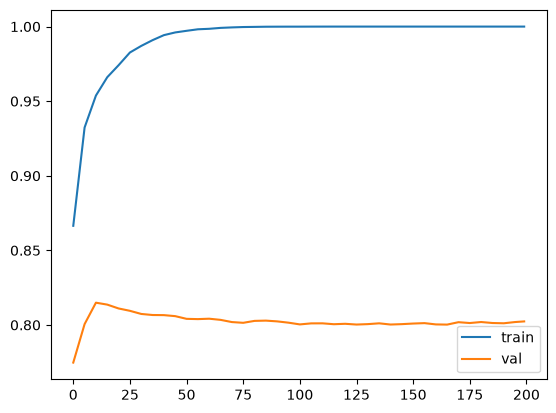

In [105]:
df_score = parse_xgb_output(output)

plt.plot(df_score.num_iter, df_score.train_auc, label='train')
plt.plot(df_score.num_iter, df_score.val_auc, label='val')
plt.legend()

In [107]:
scores = {}


In [121]:

%%capture output

xgb_params = {
    'eta': 0.1,
    'max_depth': 6,
    'min_child_weight': 1,

    'objective': 'binary:logistic',
    'eval_metric': 'auc',

    'nthread': 8,
    'seed': 1,
    'verbosity': 1,
}

model = xgb.train(xgb_params, dtrain, num_boost_round=200,
                  verbose_eval=5,
                  evals=watchlist)




In [122]:

key = 'eta=%s' % (xgb_params['eta'])
scores[key] = parse_xgb_output(output)
key

'eta=0.1'

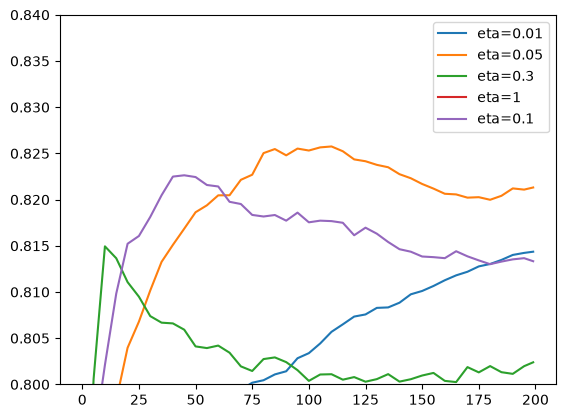

In [123]:
for key, df_score in scores.items():
    plt.plot(df_score.num_iter, df_score.val_auc, label=key)

plt.ylim(0.8, 0.84)
plt.legend()

In [124]:
##MAX DEPTH
scores = {}


In [131]:

%%capture output

xgb_params = {
    'eta': 0.1,
    'max_depth': 10,
    'min_child_weight': 1,

    'objective': 'binary:logistic',
    'eval_metric': 'auc',

    'nthread': 8,
    'seed': 1,
    'verbosity': 1,
}

model = xgb.train(xgb_params, dtrain, num_boost_round=200,
                  verbose_eval=5,
                  evals=watchlist)




In [132]:

key = 'max_depth=%s' % (xgb_params['max_depth'])
scores[key] = parse_xgb_output(output)
key

'max_depth=10'

In [134]:
del scores['max_depth=10']

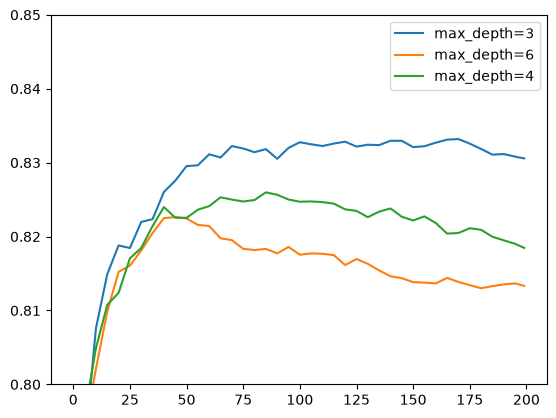

In [136]:
for key, df_score in scores.items():
    plt.plot(df_score.num_iter, df_score.val_auc, label=key)

plt.ylim(0.8,0.85)
plt.legend()

In [137]:
## max depth = 3 is the best score

In [156]:
scores = {}

In [161]:

%%capture output

xgb_params = {
    'eta': 0.1,
    'max_depth': 3,
    'min_child_weight': 30,

    'objective': 'binary:logistic',
    'eval_metric': 'auc',

    'nthread': 8,
    'seed': 1,
    'verbosity': 1,
}

model = xgb.train(xgb_params, dtrain, num_boost_round=200,
                  verbose_eval=5,
                  evals=watchlist)

In [162]:

key = 'min_child_weight=%s' % (xgb_params['min_child_weight'])
scores[key] = parse_xgb_output(output)
key

'min_child_weight=30'

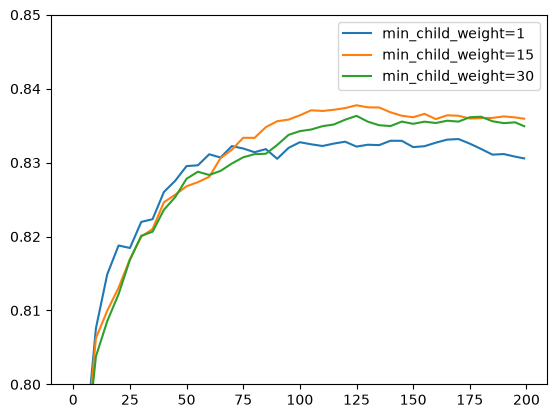

In [163]:
for key, df_score in scores.items():
    plt.plot(df_score.num_iter, df_score.val_auc, label=key)

plt.ylim(0.8,0.85)
plt.legend()

In [ ]:
### this doesn't give big difference.  so lets keep default 1, lets train 175 iter.

# Final Model 

In [164]:

%%capture output

xgb_params = {
    'eta': 0.1,
    'max_depth': 3,
    'min_child_weight': 1,

    'objective': 'binary:logistic',
    'eval_metric': 'auc',

    'nthread': 8,
    'seed': 1,
    'verbosity': 1,
}

model = xgb.train(xgb_params, dtrain, num_boost_round=175,
                  verbose_eval=5,
                  evals=watchlist)

In [165]:
y_pred = model.predict(dval)

In [166]:
roc_auc_score(y_val, y_pred)

0.8326400705867524

In [168]:
df_full_train = df_full_train.reset_index(drop=True)

In [ ]:
# Other parameters worth knowing about:

# subsample - the fraction of the training data each tree sees.
# colsample_bytree - the fraction of features each tree sees, like the random feature subsets of random forest.
# lambda and alpha - the L2 and L1 regularization terms on the weights.


In [ ]:
## comparing the three models, XG Boost is the best, with highest AUC score. hence training the entire train and validation data together to build the final model. 

In [169]:
y_full_train = (df_full_train.status=='default').astype(int).values

In [170]:
del df_full_train['status']

In [172]:
dicts_full_train = df_full_train.to_dict(orient='records')

dv = DictVectorizer(sparse=False)

X_full_train = dv.fit_transform(dicts_full_train)

dicts_test = df_test.to_dict(orient = 'records')

X_test = dv.transform(dicts_test)

In [176]:
#features = dv

features = dv.get_feature_names_out().tolist()

dfulltrain = xgb.DMatrix(X_full_train,label=y_full_train, feature_names = features)

dtest = xgb.DMatrix(X_test, feature_names = features)

In [177]:

%%capture output

xgb_params = {
    'eta': 0.1,
    'max_depth': 3,
    'min_child_weight': 1,

    'objective': 'binary:logistic',
    'eval_metric': 'auc',

    'nthread': 8,
    'seed': 1,
    'verbosity': 1,
}

model = xgb.train(xgb_params, dfulltrain, num_boost_round=175,
                  verbose_eval=5,
                  evals=watchlist)

In [179]:
y_pred = model.predict(dtest)

In [180]:
roc_auc_score(y_test,y_pred)

0.8209052820227167

In [ ]:
## the score is close to the original training score. the performance is pretty good. XGBoost turns out to be one of the best performance. It is more complex, difficult to tune. it's easier to overfit.